# F26-11 — Phase 3: Model Implementation and Training
**Lightweight Speech Emotion Recognition Using Hand-Crafted Acoustic Features**

AI2002 Artificial Intelligence (BS-SE-5A), FAST-NUCES Lahore, Fall 2026 · Track B (Research & Development)
Members: 22L-7786 (Lead), 23L-3002, 23L-3102 · Instructor: Hajra Waheed

Pipeline: Phase 2 features → split → normalise → train models → evaluate → predict the emotion of a new clip.

Models: two classical baselines (SVM, Random Forest) and the base paper's two deep models
(1D-CNN and CNN-BiLSTM), whose probabilities are averaged into an ensemble.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import sklearn
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

ROOT = Path.cwd() if (Path.cwd() / "features").exists() else Path.cwd().parent
OUT = ROOT / "phase3"
(OUT / "figures").mkdir(parents=True, exist_ok=True)
(OUT / "models").mkdir(parents=True, exist_ok=True)

SEED = 42
EMOTIONS = ["neutral", "happy", "sad", "angry", "fearful", "disgust", "surprised"]

print("tensorflow", tf.__version__, "| scikit-learn", sklearn.__version__, "| librosa", librosa.__version__)

tensorflow 2.21.0 | scikit-learn 1.6.1 | librosa 0.11.0


## 1. Load the features prepared in Phase 2
Each clip is stored as 4 versions (original, noise, pitch shift, noise + pitch) × 108 frames × 34 features
(ZCR, RMS energy, 20 MFCCs, 12 Chroma).

In [2]:
def load_features(name):
    """Load the cached feature array and the label table of one dataset."""
    X = np.load(ROOT / "features" / f"{name}.npz")["X"]
    meta = pd.read_csv(ROOT / "features" / f"{name}.csv")
    return X, meta


X_rav, meta_rav = load_features("ravdess")
X_tess, meta_tess = load_features("tess")
y_rav = meta_rav["label"].values
y_tess = meta_tess["label"].values
print("RAVDESS:", X_rav.shape, "| TESS:", X_tess.shape)

RAVDESS: (1440, 4, 108, 34) | TESS: (2800, 4, 108, 34)


## 2. Data split
RAVDESS is split as in the paper: 80% train, 10% validation, 10% test, stratified by emotion.
The split is done on clips, so the augmented copies of a test clip are never in training.
TESS is not used for training at all; it is the unseen test set of Experiment 2.

In [3]:
def random_split(y):
    """Stratified 80/10/10 split of clip indices."""
    idx = np.arange(len(y))
    train, rest = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
    val, test = train_test_split(rest, test_size=0.5, stratify=y[rest], random_state=SEED)
    return train, val, test

## 3. Model inputs
* Deep models get the paper's **3,672-value vector** (all 108 ZCR values, then RMS, then each MFCC and Chroma
  row), z-scored with the mean and std of the training set.
* Baselines get a short **68-value summary** (mean and std of each feature over time).
* Only training clips use the 3 augmented versions.

In [4]:
def get_frames(X, y, idx, augment):
    """Frame matrices and labels of the chosen clips (all 4 versions if augment, else original only)."""
    frames = X[idx] if augment else X[idx, :1]
    n_versions = frames.shape[1]
    return frames.reshape(-1, 108, 34), np.repeat(y[idx], n_versions)


def to_vectors(frames):
    """(n, 108, 34) -> (n, 3672) in the paper's order."""
    return frames.transpose(0, 2, 1).reshape(len(frames), -1)


def to_summary(frames):
    """(n, 108, 34) -> (n, 68): mean and std of every feature."""
    return np.concatenate([frames.mean(axis=1), frames.std(axis=1)], axis=1)

## 4. Models
**Baselines:** SVM with RBF kernel (C = 10) and a Random Forest with 300 trees.

**Deep models (paper Table 2):** five blocks of Conv1D → BatchNorm → MaxPool (128, 128, 64, 64, 32 filters),
dropout 0.2 after blocks 2, 4 and 5, then Dense(128) and a 7-way softmax. CNN-BiLSTM adds a bidirectional
LSTM (64 units each way) before the last block. **Training (paper Table 3):** Adam (lr 0.001), batch 64,
up to 100 epochs, early stopping on validation accuracy (patience 5), learning rate halved when validation
accuracy stalls for 3 epochs.

In [5]:
def conv_block(x, filters, kernel, dropout):
    """Conv1D -> BatchNorm -> MaxPool, with optional dropout."""
    x = layers.Conv1D(filters, kernel, padding="same", activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling1D(2, padding="same")(x)
    if dropout:
        x = layers.Dropout(0.2)(x)
    return x


def build_model(use_bilstm):
    """The paper's 1D-CNN, or CNN-BiLSTM when use_bilstm is True."""
    tf.keras.utils.set_random_seed(SEED)
    inputs = layers.Input(shape=(3672, 1))
    x = conv_block(inputs, 128, 5, dropout=False)
    x = conv_block(x, 128, 5, dropout=True)
    x = conv_block(x, 64, 5, dropout=False)
    x = conv_block(x, 64, 3, dropout=True)
    if use_bilstm:
        x = layers.Bidirectional(layers.LSTM(64, return_sequences=True))(x)
    x = conv_block(x, 32, 3, dropout=True)
    x = layers.Flatten()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    outputs = layers.Dense(len(EMOTIONS), activation="softmax")(x)
    model = models.Model(inputs, outputs, name="CNN_BiLSTM" if use_bilstm else "CNN")
    model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def train_model(model, train_x, train_y, val_x, val_y):
    """Fit a deep model with early stopping and learning-rate reduction."""
    stop_early = callbacks.EarlyStopping(monitor="val_accuracy", patience=5, restore_best_weights=True)
    lower_lr = callbacks.ReduceLROnPlateau(monitor="val_accuracy", factor=0.5, patience=3, min_lr=1e-5)
    history = model.fit(train_x[..., None], train_y, validation_data=(val_x[..., None], val_y),
                        epochs=100, batch_size=64, callbacks=[stop_early, lower_lr], verbose=2)
    return history.history


build_model(use_bilstm=True).summary()

Model: "CNN_BiLSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 3672, 1)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 3672, 128)      │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 3672, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 1836, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 1836, 128)      │        82,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1836, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 918, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 918, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 918, 64)        │        41,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 918, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 459, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 459, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 459, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 230, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 230, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 230, 128)       │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 230, 32)        │        12,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 230, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 115, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 115, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3680)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       471,168 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 688,807 (2.63 MB)

 Trainable params: 687,719 (2.62 MB)

 Non-trainable params: 1,088 (4.25 KB)

## 5. Training and prediction helpers

In [6]:
def train_all(X, y, train, val):
    """Train the two baselines and the two deep models on one split."""
    train_frames, train_y = get_frames(X, y, train, augment=True)
    val_frames, val_y = get_frames(X, y, val, augment=False)
    train_vec, val_vec = to_vectors(train_frames), to_vectors(val_frames)
    mean, std = train_vec.mean(axis=0), train_vec.std(axis=0) + 1e-8

    baselines = {
        "SVM": make_pipeline(StandardScaler(), SVC(C=10, probability=True, random_state=SEED)),
        "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED),
    }
    for model in baselines.values():
        model.fit(to_summary(train_frames), train_y)

    deep, history = {}, {}
    for name, use_bilstm in [("CNN", False), ("CNN-BiLSTM", True)]:
        print(f"--- training {name} on {len(train_y)} samples ---")
        start = time.time()
        deep[name] = build_model(use_bilstm)
        history[name] = train_model(deep[name], (train_vec - mean) / std, train_y, (val_vec - mean) / std, val_y)
        print(f"{name}: {deep[name].count_params():,} parameters, {len(history[name]['loss'])} epochs, "
              f"best val accuracy {max(history[name]['val_accuracy']):.3f}, {(time.time() - start) / 60:.1f} min")
    return {"baselines": baselines, "deep": deep, "history": history, "mean": mean, "std": std}


def predict_all(trained, frames):
    """Class probabilities of every model, plus the ensemble (average of the two deep models)."""
    summary = to_summary(frames)
    vectors = (to_vectors(frames) - trained["mean"]) / trained["std"]
    probs = {name: m.predict_proba(summary) for name, m in trained["baselines"].items()}
    probs.update({name: m.predict(vectors[..., None], verbose=0) for name, m in trained["deep"].items()})
    probs["Ensemble"] = (probs["CNN"] + probs["CNN-BiLSTM"]) / 2
    return probs


def evaluate(probs, y_true):
    """Accuracy and macro-F1 of every model."""
    rows = []
    for name, p in probs.items():
        y_pred = p.argmax(axis=1)
        rows.append({"model": name, "accuracy": accuracy_score(y_true, y_pred),
                     "macro F1": f1_score(y_true, y_pred, average="macro")})
    return pd.DataFrame(rows).set_index("model").round(3)

## 6. Experiment 1 — train and test on RAVDESS (paper protocol)

In [7]:
train, val, test = random_split(y_rav)
print(f"train {len(train)} clips (x4 = {4 * len(train)} samples) | val {len(val)} | test {len(test)}")

exp1 = train_all(X_rav, y_rav, train, val)
test_frames, test_y = get_frames(X_rav, y_rav, test, augment=False)
probs1 = predict_all(exp1, test_frames)
results1 = evaluate(probs1, test_y)
print(results1)

train 1152 clips (x4 = 4608 samples) | val 144 | test 144


--- training CNN on 4608 samples ---


Epoch 1/100


72/72 - 246s - 3s/step - accuracy: 0.5104 - loss: 1.3711 - val_accuracy: 0.2222 - val_loss: 2.8269 - learning_rate: 0.0010


Epoch 2/100


72/72 - 244s - 3s/step - accuracy: 0.7695 - loss: 0.6303 - val_accuracy: 0.2569 - val_loss: 3.3072 - learning_rate: 0.0010


... (73 outputs left out)

Epoch 21/100


72/72 - 259s - 4s/step - accuracy: 0.9998 - loss: 0.0057 - val_accuracy: 0.7778 - val_loss: 0.7487 - learning_rate: 2.5000e-04


CNN-BiLSTM: 688,807 parameters, 21 epochs, best val accuracy 0.799, 94.7 min


               accuracy  macro F1
model                            
SVM               0.771     0.767
Random Forest     0.674     0.660
CNN               0.764     0.765
CNN-BiLSTM        0.771     0.759
Ensemble          0.771     0.759


In [8]:
print(classification_report(test_y, probs1["Ensemble"].argmax(axis=1), target_names=EMOTIONS, digits=3))

              precision    recall  f1-score   support

     neutral      0.763     1.000     0.866        29
       happy      0.706     0.632     0.667        19
         sad      0.684     0.684     0.684        19
       angry      0.889     0.842     0.865        19
     fearful      0.812     0.650     0.722        20
     disgust      0.696     0.842     0.762        19
   surprised      0.923     0.632     0.750        19

    accuracy                          0.771       144
   macro avg      0.782     0.755     0.759       144
weighted avg      0.781     0.771     0.766       144



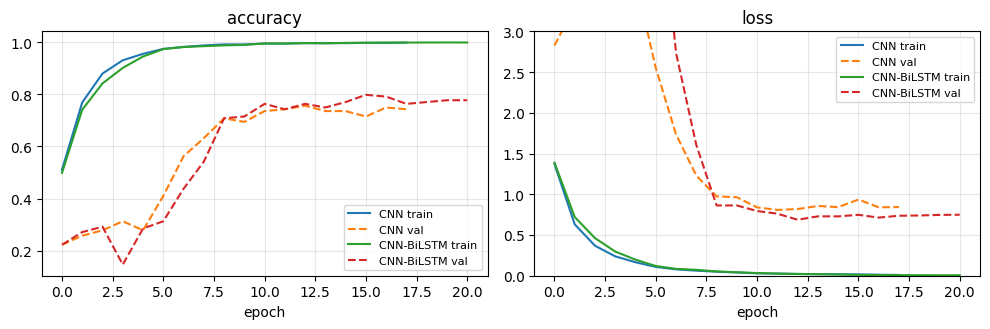

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for name, h in exp1["history"].items():
    ax[0].plot(h["accuracy"], label=f"{name} train")
    ax[0].plot(h["val_accuracy"], "--", label=f"{name} val")
    ax[1].plot(h["loss"], label=f"{name} train")
    ax[1].plot(h["val_loss"], "--", label=f"{name} val")
ax[0].set_title("accuracy"); ax[1].set_title("loss"); ax[1].set_ylim(0, 3)
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=0.3); a.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT / "figures" / "fig1_training_curves.png", dpi=200)
plt.show()

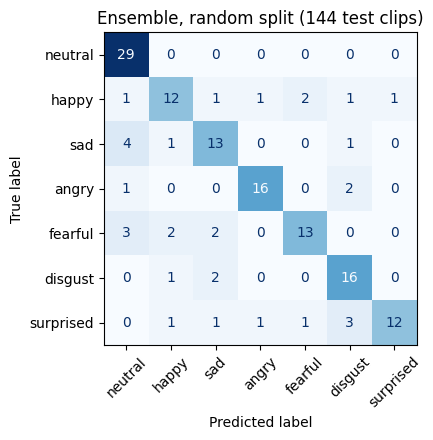

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(test_y, probs1["Ensemble"].argmax(axis=1), display_labels=EMOTIONS,
                                        cmap="Blues", colorbar=False, ax=ax, xticks_rotation=45)
ax.set_title("Ensemble, random split (144 test clips)")
plt.tight_layout()
plt.savefig(OUT / "figures" / "fig2_confusion_matrix.png", dpi=200)
plt.show()

## 7. Experiment 2 — unseen dataset (the same models tested on all 2,800 TESS clips)
No TESS data is used for training or normalisation.

In [11]:
tess_frames, tess_y = get_frames(X_tess, y_tess, np.arange(len(y_tess)), augment=False)
probs2 = predict_all(exp1, tess_frames)
results2 = evaluate(probs2, tess_y)
print(results2)

               accuracy  macro F1
model                            
SVM               0.224     0.156
Random Forest     0.308     0.253
CNN               0.230     0.208
CNN-BiLSTM        0.171     0.185
Ensemble          0.210     0.199


## 8. Summary of initial results

In [12]:
summary = pd.concat({"RAVDESS test": results1, "TESS (unseen dataset)": results2}, axis=1)
summary.to_csv(OUT / "results.csv")
print(summary)

              RAVDESS test          TESS (unseen dataset)         
                  accuracy macro F1              accuracy macro F1
model                                                             
SVM                  0.771    0.767                 0.224    0.156
Random Forest        0.674    0.660                 0.308    0.253
CNN                  0.764    0.765                 0.230    0.208
CNN-BiLSTM           0.771    0.759                 0.171    0.185
Ensemble             0.771    0.759                 0.210    0.199


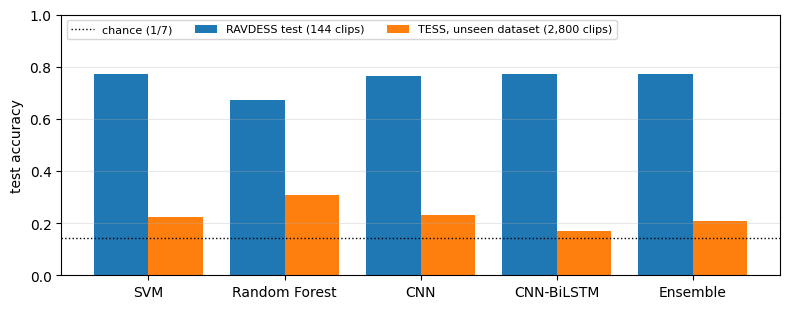

In [13]:
names = list(results1.index)
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(x - 0.2, results1["accuracy"], width=0.4, label="RAVDESS test (144 clips)")
ax.bar(x + 0.2, results2["accuracy"], width=0.4, label="TESS, unseen dataset (2,800 clips)")
ax.axhline(1 / 7, color="k", ls=":", lw=1, label="chance (1/7)")
ax.set_xticks(x, names); ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1)
ax.legend(fontsize=8, ncol=3, loc="upper left"); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(OUT / "figures" / "fig3_results.png", dpi=200)
plt.show()

In [14]:
for name, model in exp1["deep"].items():
    model.save(OUT / "models" / f"{name}.keras")
np.savez(OUT / "models" / "normalizer.npz", mean=exp1["mean"], std=exp1["std"])
print("saved models to", OUT / "models")

saved models to C:\Users\user\Desktop\Ai-project\phase3\models


## 9. Using the model: from a .wav file to an emotion
`extract_features` repeats the Phase 2 feature pipeline for a single file: load 2.5 s from 0.6 s at
22,050 Hz, compute ZCR, RMS, 20 MFCCs and 12 Chroma for 108 frames, and fill missing frames with zeros.

In [15]:
def extract_features(path):
    """One .wav file -> (108, 34) feature matrix."""
    audio, sr = librosa.load(path, sr=22050, offset=0.6, duration=2.5)
    zcr = librosa.feature.zero_crossing_rate(audio, frame_length=2048, hop_length=512)
    rms = librosa.feature.rms(y=audio, frame_length=2048, hop_length=512)
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=20, n_fft=2048, hop_length=512)
    chroma = librosa.feature.chroma_stft(y=audio, sr=sr, n_fft=2048, hop_length=512)
    features = np.vstack([zcr, rms, mfcc, chroma]).T
    frames = np.zeros((108, 34), dtype=np.float32)
    n = min(108, len(features))
    frames[:n] = features[:n]
    return np.nan_to_num(frames)


def predict_emotion(path, trained):
    """Predicted emotion and confidence of the ensemble for one .wav file."""
    frames = extract_features(path)[None]
    probs = predict_all(trained, frames)["Ensemble"][0]
    return EMOTIONS[probs.argmax()], probs.max()


for i in test[:6]:
    path = ROOT / meta_rav["path"][i].replace("\\", "/")
    emotion, confidence = predict_emotion(path, exp1)
    print(f"{path.name}: true = {meta_rav['emotion'][i]:9s} predicted = {emotion:9s} ({confidence:.0%})")

i = test[0]
check = extract_features(ROOT / meta_rav["path"][i].replace("\\", "/"))
print("max difference from the Phase 2 cached features:", np.abs(check - X_rav[i, 0]).max())

C:\Users\user\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


03-01-01-01-01-02-21.wav: true = neutral   predicted = neutral   (79%)


03-01-06-02-02-02-08.wav: true = fearful   predicted = fearful   (100%)


03-01-06-01-01-01-15.wav: true = fearful   predicted = sad       (100%)


03-01-05-02-02-01-15.wav: true = angry     predicted = angry     (82%)


03-01-02-02-02-01-05.wav: true = neutral   predicted = neutral   (58%)


03-01-02-02-01-02-09.wav: true = neutral   predicted = neutral   (42%)
max difference from the Phase 2 cached features: 0.0
